<a href="https://colab.research.google.com/github/FoadZahediLabaf/NDA-Labs/blob/main/MAC_De-randomization/MAC_De-randomization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import os

lecture_dir = "/content/lecture_dataset"

# read all csv files from the lecture dataset
df_list = []

for file in os.listdir(lecture_dir):
    if file.endswith(".csv"):
        file_path = os.path.join(lecture_dir, file)
        df = pd.read_csv(file_path)
        df_list.append(df)

lecture_df = pd.concat(df_list, ignore_index=True)

# same conversion used in class material
lecture_df["Timestamp"] = pd.to_datetime(lecture_df["Timestamp"], unit="s")

print("Original shape:", lecture_df.shape)
print("\nOriginal columns:")
print(lecture_df.columns.tolist())

# check missing values
nan_sum = lecture_df.isna().sum()
nan_percentage = (nan_sum / len(lecture_df)) * 100

print("\nNaN percentage:")
print(nan_percentage)

# drop columns with too many missing values, same simple idea used in class
col_drop = []

for col in nan_percentage.index:
    if nan_percentage[col] > 60:
        col_drop.append(col)

print("\nDropped columns:")
print(col_drop)

clean_lecture_df = lecture_df.drop(columns=col_drop).copy()

print("\nCleaned shape:", clean_lecture_df.shape)
print("\nCleaned columns:")
print(clean_lecture_df.columns.tolist())

display(clean_lecture_df.head())

Original shape: (4988, 14)

Original columns:
['Timestamp', 'MAC Address', 'Channel', 'DS Channel', 'HT Capabilities', 'Extended Capabilities', 'Vendor Specific Tags', 'SSID', 'Supported Rates', 'Extended Supported Rates', 'VHT Capabilities', 'HE Capabilities', 'Length', 'Label']

NaN percentage:
Timestamp                     0.000000
MAC Address                   0.000000
Channel                       0.000000
DS Channel                    0.581395
HT Capabilities               0.020048
Extended Capabilities         0.020048
Vendor Specific Tags         18.905373
SSID                         91.439455
Supported Rates               0.000000
Extended Supported Rates      0.020048
VHT Capabilities            100.000000
HE Capabilities              81.295108
Length                        0.000000
Label                         0.000000
dtype: float64

Dropped columns:
['SSID', 'VHT Capabilities', 'HE Capabilities']

Cleaned shape: (4988, 11)

Cleaned columns:
['Timestamp', 'MAC Address', '

,Timestamp,MAC Address,Channel,DS Channel,HT Capabilities,Extended Capabilities,Vendor Specific Tags,Supported Rates,Extended Supported Rates,Length,Label
0,2021-06-21 11:27:03.423060894,56:76:96:fe:e3:51,1,1.0,2d0017ff00000000000000000000000000000000000000...,8.000000e+10,NaN,02040b16,0c1218243048606c,113,iPhoneXR-U
1,2021-06-21 11:27:03.473134995,56:76:96:fe:e3:51,11,11.0,2d0017ff00000000000000000000000000000000000000...,8.000000e+10,NaN,02040b16,0c1218243048606c,113,iPhoneXR-U
2,2021-06-21 11:29:18.421873093,f2:e7:86:51:24:57,1,1.0,2d0017ff00000000000000000000000000000000000000...,8.000000e+10,NaN,02040b16,0c1218243048606c,113,iPhoneXR-U
3,2021-06-21 11:29:18.471878052,f2:e7:86:51:24:57,11,11.0,2d0017ff00000000000000000000000000000000000000...,8.000000e+10,NaN,02040b16,0c1218243048606c,113,iPhoneXR-U
4,2021-06-21 11:33:48.417167902,5a:92:46:6a:3a:e7,1,1.0,2d0017ff00000000000000000000000000000000000000...,8.000000e+10,NaN,02040b16,0c1218243048606c,113,iPhoneXR-U


In [ ]:
# sort probes in time order for online clustering
clean_lecture_df = clean_lecture_df.sort_values("Timestamp").reset_index(drop=True)

# feature columns used for matching
feature_cols = [
    "Channel",
    "DS Channel",
    "HT Capabilities",
    "Extended Capabilities",
    "Vendor Specific Tags",
    "Supported Rates",
    "Extended Supported Rates",
    "Length"
]

work_lecture_df = clean_lecture_df.copy()

# simple handling of missing values for feature comparison
for col in feature_cols:
    work_lecture_df[col] = work_lecture_df[col].fillna("MISSING").astype(str)

print("Number of probes:", len(work_lecture_df))
print("\nFeature columns used:")
print(feature_cols)

print("\nLabels in lecture dataset:")
print(work_lecture_df["Label"].value_counts())

display(work_lecture_df[["Timestamp"] + feature_cols + ["Label"]].head())

Number of probes: 4988

Feature columns used:
['Channel', 'DS Channel', 'HT Capabilities', 'Extended Capabilities', 'Vendor Specific Tags', 'Supported Rates', 'Extended Supported Rates', 'Length']

Labels in lecture dataset:
Label
HuaweiHonor9_R    2394
iPhone6_N          787
SamsungJ6_K        728
iPhone11-C_a       531
iPhone12_W         263
iPhoneXR-U         146
S21Ultra-M_a       139
Name: count, dtype: int64


,Timestamp,Channel,DS Channel,HT Capabilities,Extended Capabilities,Vendor Specific Tags,Supported Rates,Extended Supported Rates,Length,Label
0,2021-05-31 14:12:39.190361023,6,6.0,214017ff00000000000000000000000000000000000000...,400088400000040.0,0017f20a00010400000000,02040b16,0c1218243048606c,156,iPhone6_N
1,2021-05-31 14:12:39.210052967,6,6.0,214017ff00000000000000000000000000000000000000...,400088400000040.0,0017f20a00010400000000,02040b16,0c1218243048606c,156,iPhone6_N
2,2021-05-31 14:12:39.231878996,6,7.0,214017ff00000000000000000000000000000000000000...,400088400000040.0,0017f20a00010400000000,02040b16,0c1218243048606c,156,iPhone6_N
3,2021-05-31 14:12:39.252192020,6,7.0,214017ff00000000000000000000000000000000000000...,400088400000040.0,0017f20a00010400000000,02040b16,0c1218243048606c,156,iPhone6_N
4,2021-05-31 14:12:39.273920059,6,8.0,214017ff00000000000000000000000000000000000000...,400088400000040.0,0017f20a00010400000000,02040b16,0c1218243048606c,156,iPhone6_N


In [ ]:
from sklearn.metrics import v_measure_score
import numpy as np

def count_feature_matches(row_features, cluster_features, feature_cols):
    matches = 0
    for col in feature_cols:
        if row_features[col] == cluster_features[col]:
            matches += 1
    return matches

def online_clustering(df, feature_cols, N):
    clusters = []
    predicted_clusters = []

    for _, row in df.iterrows():
        row_features = {col: row[col] for col in feature_cols}

        assigned_cluster = None

        # first match wins
        for cluster_id, cluster in enumerate(clusters):
            match_count = count_feature_matches(row_features, cluster["features"], feature_cols)

            if match_count >= N:
                assigned_cluster = cluster_id
                break

        if assigned_cluster is None:
            new_cluster = {
                "features": row_features.copy()
            }
            clusters.append(new_cluster)
            assigned_cluster = len(clusters) - 1

        predicted_clusters.append(assigned_cluster)

    return predicted_clusters, clusters

# try one exanple value of N
N = 6

pred_clusters, clusters = online_clustering(work_lecture_df, feature_cols, N)

true_labels = work_lecture_df["Label"].astype(str).tolist()

vscore = v_measure_score(true_labels, pred_clusters)

# simple error measure:
# for each cluster, assign the majority true label
cluster_to_majority_label = {}
for cluster_id in sorted(set(pred_clusters)):
    cluster_labels = [true_labels[i] for i in range(len(true_labels)) if pred_clusters[i] == cluster_id]
    majority_label = max(set(cluster_labels), key=cluster_labels.count)
    cluster_to_majority_label[cluster_id] = majority_label

predicted_labels = [cluster_to_majority_label[c] for c in pred_clusters]

classification_error = np.mean([
    1 if predicted_labels[i] != true_labels[i] else 0
    for i in range(len(true_labels))
])

rmse = np.sqrt(classification_error)

print("Chosen N:", N)
print("Number of cluster created:", len(clusters))
print("V-measure:", vscore)
print("Classification error:", classification_error)
print("RMSE:", rmse)

print("\nFirst 20 predicted cluster ids:")
print(pred_clusters[:20])

Chosen N: 6
Number of cluster created: 16
V-measure: 0.8476061484521776
Classification error: 0.04851643945469126
RMSE: 0.22026447615240016

First 20 predicted cluster ids:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]


In [ ]:
import pandas as pd
import numpy as np

# We test all possible values of N and then select the best one.
# This follows the homework request: test different N and choose the one
# that gives the best clustering performance.

results = []

true_labels = work_lecture_df["Label"].astype(str).tolist()
true_num_devices = len(set(true_labels))

for N in range(1, len(feature_cols) + 1):
    pred_clusters, clusters = online_clustering(work_lecture_df, feature_cols, N)

    vscore = v_measure_score(true_labels, pred_clusters)

    # Majority-label mapping for each cluster
    cluster_to_majority_label = {}
    for cluster_id in sorted(set(pred_clusters)):
        cluster_labels = [
            true_labels[i]
            for i in range(len(true_labels))
            if pred_clusters[i] == cluster_id
        ]
        majority_label = max(set(cluster_labels), key=cluster_labels.count)
        cluster_to_majority_label[cluster_id] = majority_label

    predicted_labels = [cluster_to_majority_label[c] for c in pred_clusters]

    classification_error = np.mean([
        1 if predicted_labels[i] != true_labels[i] else 0
        for i in range(len(true_labels))
    ])

    rmse = np.sqrt(classification_error)
    num_clusters = len(clusters)
    cluster_diff = abs(num_clusters - true_num_devices)

    results.append({
        "N": N,
        "num_clusters": num_clusters,
        "true_num_devices": true_num_devices,
        "cluster_diff": cluster_diff,
        "v_measure": vscore,
        "classification_error": classification_error,
        "rmse": rmse
    })

results_df = pd.DataFrame(results)

print("Results for all N:")
display(results_df)

# Final choice: use v-measure as the main clustering metric
best_row = results_df.loc[results_df["v_measure"].idxmax()]
best_N = int(best_row["N"])

print("\nSelected best N (by highest v-measure):")
print(best_row)

print("\nFinal selected best_N =", best_N)

Results for all N:


,N,num_clusters,true_num_devices,cluster_diff,v_measure,classification_error,rmse
0,1,2,7,5,0.014006,0.514435,0.717241
1,2,3,7,4,0.249945,0.448677,0.669833
2,3,7,7,0,0.435432,0.296913,0.544897
3,4,9,7,2,0.664285,0.170409,0.412806
4,5,10,7,3,0.926645,0.061347,0.247684
5,6,16,7,9,0.847606,0.048516,0.220264
6,7,31,7,24,0.707263,0.020650,0.143700
7,8,146,7,139,0.521432,0.000000,0.000000



Selected best N (by highest v-measure):
N                        5.000000
num_clusters            10.000000
true_num_devices         7.000000
cluster_diff             3.000000
v_measure                0.926645
classification_error     0.061347
rmse                     0.247684
Name: 4, dtype: float64

Final selected best_N = 5


In [ ]:
import pandas as pd
import os

challenge_dir = "/content/challenge_dataset"

df_list = []

for file in os.listdir(challenge_dir):
    if file.endswith(".csv"):
        file_path = os.path.join(challenge_dir, file)
        df = pd.read_csv(file_path)
        df_list.append(df)

challenge_df = pd.concat(df_list, ignore_index=True)

challenge_df["Timestamp"] = pd.to_datetime(challenge_df["Timestamp"], unit="s")

print("Original challenge shape:", challenge_df.shape)
print("\nOriginal challenge columns:")
print(challenge_df.columns.tolist())

nan_sum = challenge_df.isna().sum()
nan_percentage = (nan_sum / len(challenge_df)) * 100

print("\nNaN percentage in challenge dataset:")
print(nan_percentage)

col_drop = []

for col in nan_percentage.index:
    if nan_percentage[col] > 60:
        col_drop.append(col)

print("\nDropped columns in challenge dataset:")
print(col_drop)

clean_challenge_df = challenge_df.drop(columns=col_drop).copy()

clean_challenge_df = clean_challenge_df.sort_values("Timestamp").reset_index(drop=True)

for col in feature_cols:
    clean_challenge_df[col] = clean_challenge_df[col].fillna("MISSING").astype(str)

print("\nCleaned challenge shape:", clean_challenge_df.shape)
print("\nChallenge labels:")
print(clean_challenge_df["Label"].value_counts())

display(clean_challenge_df[["Timestamp"] + feature_cols + ["Label"]].head())

Original challenge shape: (7503, 14)

Original challenge columns:
['Timestamp', 'MAC Address', 'Channel', 'DS Channel', 'HT Capabilities', 'Extended Capabilities', 'Vendor Specific Tags', 'SSID', 'Supported Rates', 'Extended Supported Rates', 'VHT Capabilities', 'HE Capabilities', 'Length', 'Label']

NaN percentage in challenge dataset:
Timestamp                    0.000000
MAC Address                  0.000000
Channel                      0.000000
DS Channel                   0.000000
HT Capabilities              3.558577
Extended Capabilities        3.558577
Vendor Specific Tags        29.814741
SSID                        94.695455
Supported Rates              0.000000
Extended Supported Rates     0.000000
VHT Capabilities            81.034253
HE Capabilities             51.219512
Length                       0.000000
Label                        0.000000
dtype: float64

Dropped columns in challenge dataset:
['SSID', 'VHT Capabilities']

Cleaned challenge shape: (7503, 12)

Challeng

,Timestamp,Channel,DS Channel,HT Capabilities,Extended Capabilities,Vendor Specific Tags,Supported Rates,Extended Supported Rates,Length,Label
0,2021-05-21 09:19:54.305140972,1,1,2d0117ff00000000000000000000000000000000000000...,10008000000004080,0050f208001100,02040b160c121824,3048606c,123,SamsungM31_A
1,2021-05-21 09:19:54.341902971,1,1,2d0117ff00000000000000000000000000000000000000...,10008000000004080,0050f208001100,02040b160c121824,3048606c,123,SamsungM31_A
2,2021-05-21 09:19:54.417952061,1,2,2d0117ff00000000000000000000000000000000000000...,10008000000004080,0050f208001100,02040b160c121824,3048606c,123,SamsungM31_A
3,2021-05-21 09:19:54.457884073,1,3,2d0117ff00000000000000000000000000000000000000...,10008000000004080,0050f208001100,02040b160c121824,3048606c,123,SamsungM31_A
4,2021-05-21 09:19:54.494689941,1,3,2d0117ff00000000000000000000000000000000000000...,10008000000004080,0050f208001100,02040b160c121824,3048606c,123,SamsungM31_A


In [ ]:
import random
import pandas as pd
import numpy as np
from sklearn.metrics import v_measure_score

random.seed(42)

challenge_labels = sorted(clean_challenge_df["Label"].unique().tolist())

validation_results = []

for K in [2, 3, 4, 5, 6]:
    if K < 6:
        selected_device_sets = []
        used_sets = set()

        while len(selected_device_sets) < 5:
            sampled = tuple(sorted(random.sample(challenge_labels, K)))
            if sampled not in used_sets:
                used_sets.add(sampled)
                selected_device_sets.append(list(sampled))
    else:
        selected_device_sets = [challenge_labels.copy()]

    for test_id, selected_devices in enumerate(selected_device_sets, start=1):
        test_df = clean_challenge_df[clean_challenge_df["Label"].isin(selected_devices)].copy()
        test_df = test_df.sort_values("Timestamp").reset_index(drop=True)

        pred_clusters, clusters = online_clustering(test_df, feature_cols, best_N)

        true_labels = test_df["Label"].astype(str).tolist()
        vscore = v_measure_score(true_labels, pred_clusters)

        # majority-label mapping
        cluster_to_majority_label = {}
        for cluster_id in sorted(set(pred_clusters)):
            cluster_labels = [
                true_labels[i]
                for i in range(len(true_labels))
                if pred_clusters[i] == cluster_id
            ]
            majority_label = max(set(cluster_labels), key=cluster_labels.count)
            cluster_to_majority_label[cluster_id] = majority_label

        predicted_labels = [cluster_to_majority_label[c] for c in pred_clusters]

        classification_error = np.mean([
            1 if predicted_labels[i] != true_labels[i] else 0
            for i in range(len(true_labels))
        ])

        rmse = np.sqrt(classification_error)

        validation_results.append({
            "K": K,
            "test_id": test_id,
            "selected_devices": ", ".join(selected_devices),
            "num_probes": len(test_df),
            "num_clusters": len(clusters),
            "v_measure": vscore,
            "classification_error": classification_error,
            "rmse": rmse
        })

validation_results_df = pd.DataFrame(validation_results)

print("Validation results on challenge dataset:")
display(validation_results_df)

Validation results on challenge dataset:


,K,test_id,selected_devices,num_probes,num_clusters,v_measure,classification_error,rmse
0,2,1,"GooglePixel3A_V, iPhone12_W",2504,3,0.957210,0.000000,0.000000
1,2,2,"GooglePixel3A_V, SamsungM31_A",752,3,0.927934,0.000000,0.000000
2,2,3,"HuaweiHonor9_R, iPhone12_W",4631,2,1.000000,0.000000,0.000000
3,2,4,"GooglePixel3A_V, HuaweiHonor9_R",2661,3,0.958020,0.000000,0.000000
4,2,5,"XiaomiRedmiNote9S_T, iPhone12_W",3660,3,0.970384,0.000000,0.000000
5,3,1,"GooglePixel3A_V, SamsungS7_I, XiaomiRedmiNote9S_T",2387,5,0.921597,0.005865,0.076584
6,3,2,"GooglePixel3A_V, XiaomiRedmiNote9S_T, iPhone12_W",3927,5,0.949254,0.003565,0.059708
7,3,3,"GooglePixel3A_V, HuaweiHonor9_R, iPhone12_W",4898,4,0.991127,0.000000,0.000000
8,3,4,"HuaweiHonor9_R, SamsungS7_I, XiaomiRedmiNote9S_T",4514,4,0.836339,0.057377,0.239535
9,3,5,"HuaweiHonor9_R, SamsungM31_A, SamsungS7_I",3576,3,0.784569,0.072427,0.269123


In [ ]:
avg_results_df = (
    validation_results_df
    .groupby("K")[["v_measure", "classification_error", "rmse", "num_clusters", "num_probes"]]
    .mean()
    .reset_index()
)

print("Average performance vs K:")
display(avg_results_df)

Average performance vs K:


,K,v_measure,classification_error,rmse,num_clusters,num_probes
0,2,0.962710,0.000000,0.000000,2.8,2841.6
1,3,0.896577,0.027847,0.128990,4.2,3860.4
2,4,0.909333,0.032281,0.158617,5.6,4882.2
3,5,0.923453,0.034238,0.173172,6.6,6481.2
4,6,0.927133,0.036385,0.190750,8.0,7503.0


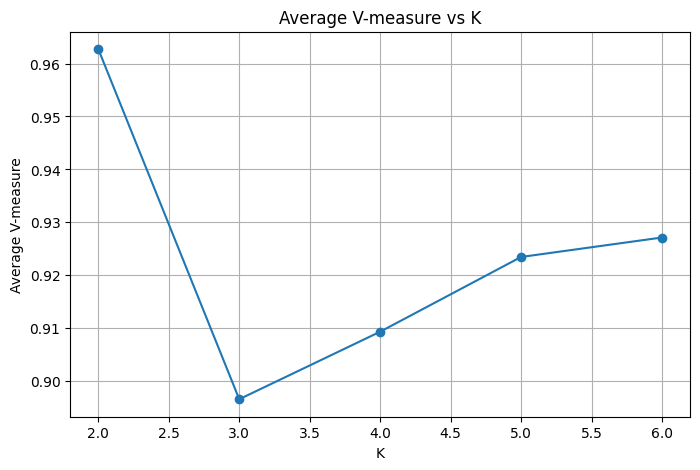

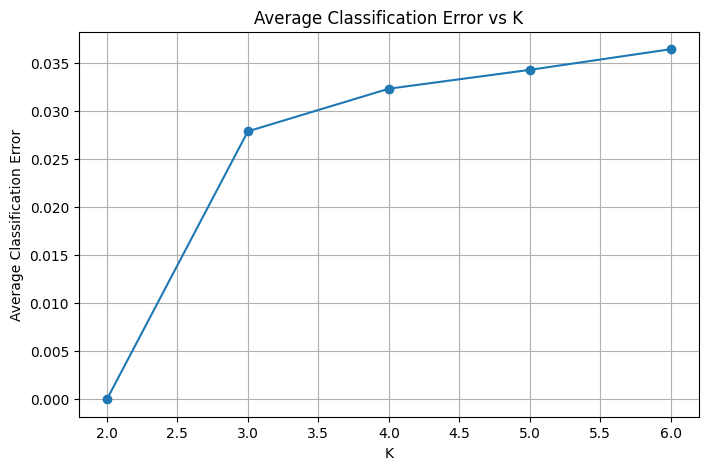

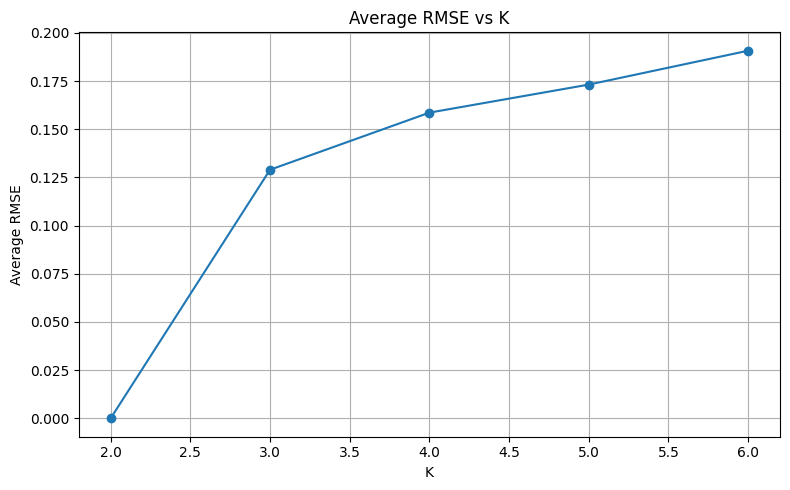

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(avg_results_df["K"], avg_results_df["v_measure"], marker="o")
plt.xlabel("K")
plt.ylabel("Average V-measure")
plt.title("Average V-measure vs K")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(avg_results_df["K"], avg_results_df["classification_error"], marker="o")
plt.xlabel("K")
plt.ylabel("Average Classification Error")
plt.title("Average Classification Error vs K")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(avg_results_df["K"], avg_results_df["rmse"], marker="o")
plt.xlabel("K")
plt.ylabel("Average RMSE")
plt.title("Average RMSE vs K")
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# adjust the filename only if Colab shows a slightly different exact name
unlabeled_path = "/content/MAC_derand_unlabelled-challenge.csv"

unlabeled_df = pd.read_csv(unlabeled_path)

# same preprocessing style used before
unlabeled_df["Timestamp"] = pd.to_datetime(unlabeled_df["Timestamp"], unit="s")

# drop the same high-NaN columns used in the lecture/challenge workflow when present
cols_to_drop_if_present = ["SSID", "VHT Capabilities", "HE Capabilities"]
existing_cols_to_drop = [col for col in cols_to_drop_if_present if col in unlabeled_df.columns]
clean_unlabeled_df = unlabeled_df.drop(columns=existing_cols_to_drop).copy()

# sort by time for online clustering
clean_unlabeled_df = clean_unlabeled_df.sort_values("Timestamp").reset_index(drop=True)

# use the same feature columns and same simple missing-value handling
for col in feature_cols:
    clean_unlabeled_df[col] = clean_unlabeled_df[col].fillna("MISSING").astype(str)

# run online clustering with the selected threshold
pred_clusters_unlabeled, unlabeled_clusters = online_clustering(clean_unlabeled_df, feature_cols, best_N)

estimated_num_devices = len(unlabeled_clusters)

print("Selected best_N:", best_N)
print("Number of probes in unlabeled dataset:", len(clean_unlabeled_df))
print("Estimated number of devices in unlabeled dataset:", estimated_num_devices)

print("\nFirst 20 predicted cluster ids:")
print(pred_clusters_unlabeled[:20])

Selected best_N: 5
Number of probes in unlabeled dataset: 20464
Estimated number of devices in unlabeled dataset: 10

First 20 predicted cluster ids:
[0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1]


In this homework, I used the given MAC randomization datasets and built a simple online clustering method for probe requests. First, I loaded the lecture dataset and cleaned it a little by converting the timestamp and removing columns with too many missing values. After that, I processed the probe requests one by one in time order. For each new probe, I checked if it matched an already existing cluster. If at least N features matched, I assigned it to that cluster. Otherwise, I created a new cluster. If more than one cluster matched, I just used the first one.
Then I tested different values of N on the lecture dataset to see which one works better. The best value was N=5, because it gave the highest v-measure and also did not create too many clusters. After choosing this value, I used the same method on the challenge dataset. I tested different values of K, which means different number of devices in the test set. For K=2,3,4,5, I used five random test sets, and for K=6 I used the full dataset. The results were good overall. When the number of devices became larger, the problem became a bit harder, which is normal.
At the end, I used the same best setting on the unlabeled challenge dataset. With N=5, the method estimated that the unlabeled dataset contains 10 devices.